# Отчёт по лабораторной работе №7 по теме «Классификация»

**Выполнил:** студент группы 12002408

Блинов Кирилл Игоревич

**Проверил:** ассистент кафедры информационных и робототехнических систем

Пузырев Никита Сергеевич


<p align="justify"><strong>Цель работы:</strong> изучить подготовку данных и построение модели классификации методом ближайших соседей.</p>


<h2 align="center">Задание</h2>

Подготовить данные Titanic, построить модель предсказания выживания пассажиров и оценить её по матрице ошибок и accuracy.


## Ход работы


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

%matplotlib inline

plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11
pd.set_option('display.max_columns', None)


### Задание №1. Создание DataFrame

Создать DataFrame из файла titanic.csv, используя столбец PassengerId в качестве индекса.


In [2]:
csv_path = Path('data/titanic.csv')
if not csv_path.exists():
    csv_path = Path('les07/data/titanic.csv')
if csv_path.exists():
    df = pd.read_csv(csv_path, index_col='PassengerId')
else:
    df = pd.read_csv(
        'https://raw.githubusercontent.com/kir1lka/dap-2024/main/les07/data/titanic.csv',
        index_col='PassengerId'
    )

print('Размер таблицы:', df.shape)
print('Название индекса:', df.index.name)


Размер таблицы: (891, 11)
Название индекса: PassengerId


### Задание №2. Первые строки набора

Вывести первые 7 строк набора.


In [3]:
df.head(7)


,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S


### Задание №3. Типы данных и пропуски

Вывести информацию о типах данных, определить нечисловые признаки и наличие null.


In [4]:
df.info()
print('\nНечисловые столбцы:')
print(df.select_dtypes(exclude='number').columns.tolist())
print('\nКоличество пропусков:')
print(df.isnull().sum())


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    str    
 3   Sex       891 non-null    str    
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    str    
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    str    
 10  Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 76.7 KB

Нечисловые столбцы:
['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']

Количество пропусков:
Survived      0
Pclass        0
Name          0
Sex           0
Age         177
SibSp         0
Parch         0
Ticket        0
Fare          0
Cabin       687
Embarked      2
dtype: int64


Нечисловые признаки: Name, Sex, Ticket, Cabin и Embarked. В Age есть
177 пропусков, в Cabin – 687, в Embarked – 2. Остальные столбцы заполнены.


### Задание №4. Удаление строковых признаков

Удалить нечисловые признаки, которые не используются в выбранном варианте модели.


In [5]:
df = df.drop(columns=['Name', 'Ticket', 'Cabin'])
print('Оставшиеся столбцы:')
print(df.columns.tolist())


Оставшиеся столбцы:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


В данном варианте не используются сырые строки имени, номера билета
и каюты: они имеют много различных значений, а Cabin преимущественно
не заполнен. Из этих полей можно было бы извлечь дополнительные
признаки, например обращение в имени или палубу. Здесь используется
простая модель по готовым числовым признакам. Sex и Embarked сохранены
для дальнейшего кодирования. PassengerId служит индексом и не входит
в признаки модели.


### Задание №5. Кодирование пола

Вместо Sex создать два признака male и female со значениями 0 или 1.


In [6]:
sex_columns = pd.get_dummies(df['Sex'], dtype=int)[['male', 'female']]
df = pd.concat([df.drop(columns='Sex'), sex_columns], axis=1)
df[['male', 'female']].head(7)


,male,female
PassengerId,,
1,1,0
2,0,1
3,0,1
4,0,1
5,1,0
6,1,0
7,1,0


### Задание №6. Удаление пропущенных значений

Удалить строки, содержащие хотя бы одно null-значение.


In [7]:
rows_before = len(df)
df = df.dropna().copy()
print('Строк до удаления:', rows_before)
print('Удалено строк:', rows_before - len(df))
print('Осталось строк:', len(df))
print('Осталось пропусков:', df.isnull().sum().sum())

df = pd.get_dummies(df, columns=['Embarked'], prefix='Embarked', dtype=int)
print('\nЧисловая таблица после кодирования порта посадки:')
display(df.head())


Строк до удаления: 891
Удалено строк: 179
Осталось строк: 712
Осталось пропусков: 0

Числовая таблица после кодирования порта посадки:


,Survived,Pclass,Age,SibSp,Parch,Fare,male,female,Embarked_C,Embarked_Q,Embarked_S
PassengerId,,,,,,,,,,,
1,0,3,22.0,1,0,7.2500,1,0,0,0,1
2,1,1,38.0,1,0,71.2833,0,1,1,0,0
3,1,3,26.0,0,0,7.9250,0,1,0,0,1
4,1,1,35.0,1,0,53.1000,0,1,0,0,1
5,0,3,35.0,0,0,8.0500,1,0,0,0,1


После удаления пропусков осталось 712 пассажиров. Порт посадки
кодируется в Embarked_C, Embarked_Q и Embarked_S после удаления строк,
чтобы пропущенный порт не превратился в набор нулей и не потерялся
при проверке. Все признаки теперь представлены числами.


### Задание №7. Нормализация Fare

Нормализовать значения признака Fare.


In [8]:
model_data = df.copy()
fare_scaler = StandardScaler()
df[['Fare']] = fare_scaler.fit_transform(df[['Fare']])
print('Среднее нормализованного Fare:', round(df['Fare'].mean(), 6))
print('Стандартное отклонение Fare:', round(df['Fare'].std(ddof=0), 6))
display(df[['Fare']].head())


Среднее нормализованного Fare: -0.0
Стандартное отклонение Fare: 1.0


,Fare
PassengerId,
1,-0.516380
2,0.694046
3,-0.503620
4,0.350326
5,-0.501257


Как в лекционном примере, используется стандартизация: из значения
вычитается среднее, затем результат делится на стандартное отклонение.
Среднее Fare становится близким к нулю, стандартное отклонение – к единице.
Отрицательный результат означает платёж ниже среднего.

model_data сохраняет исходные числовые данные до этой операции.
Стандартизированный Fare используется для исследования и гистограмм,
а масштабирование всех входов модели будет обучено только на
тренировочной части с помощью Pipeline.


### Задание №8. Разница средних платежей

Найти разницу средних значений Fare для погибших и выживших пассажиров.


In [9]:
fare_means = df.groupby('Survived')['Fare'].mean()
fare_difference = fare_means.loc[1] - fare_means.loc[0]
print(f'Среднее Fare погибших: {fare_means.loc[0]:.4f}')
print(f'Среднее Fare выживших: {fare_means.loc[1]:.4f}')
print(f'Разница (выжившие минус погибшие): {fare_difference:.4f}')
print(f'Модуль разницы: {abs(fare_difference):.4f}')


Среднее Fare погибших: -0.2193
Среднее Fare выживших: 0.3229
Разница (выжившие минус погибшие): 0.5422
Модуль разницы: 0.5422


Средний нормализованный платёж у выживших выше. Это наблюдаемая связь в данных, которая сама по себе не устанавливает причину выживания.


### Задание №9. Гистограммы Fare

Построить на одной оси гистограммы Fare для погибших и выживших пассажиров.


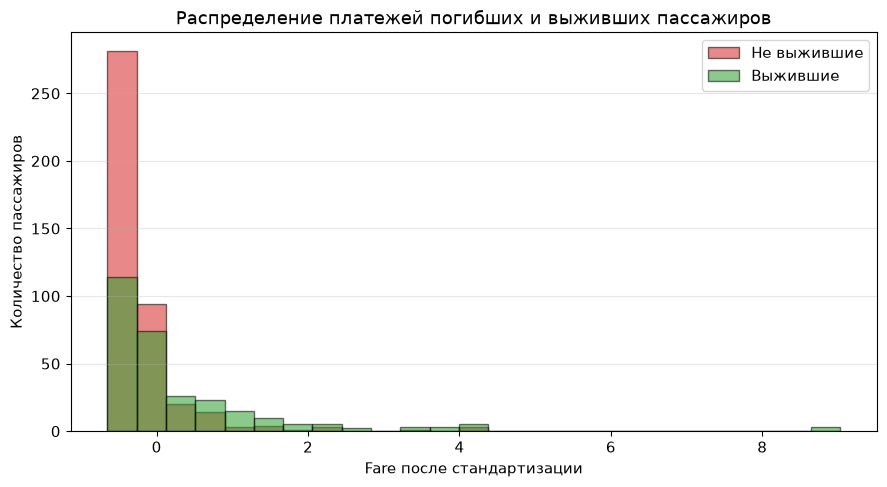

In [10]:
fare_bins = np.linspace(df['Fare'].min(), df['Fare'].max(), 26)
fig, ax = plt.subplots()
ax.hist(df.loc[df['Survived'] == 0, 'Fare'], bins=fare_bins, alpha=0.55,
        color='tab:red', edgecolor='black', label='Не выжившие')
ax.hist(df.loc[df['Survived'] == 1, 'Fare'], bins=fare_bins, alpha=0.55,
        color='tab:green', edgecolor='black', label='Выжившие')
ax.set(xlabel='Fare после стандартизации', ylabel='Количество пассажиров',
       title='Распределение платежей погибших и выживших пассажиров')
ax.legend()
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
plt.show()


### Задание №10. Набор признаков и целевые значения

Сформировать набор признаков X и вектор целевых значений y.


In [11]:
X = model_data.drop(columns='Survived')
y = model_data['Survived']
print('Признаки модели:', X.columns.tolist())
print('Размер X:', X.shape)
print('Размер y:', y.shape)
print('\nКоличество объектов каждого класса:')
print(y.value_counts().sort_index())


Признаки модели: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'male', 'female', 'Embarked_C', 'Embarked_Q', 'Embarked_S']
Размер X: (712, 10)
Размер y: (712,)

Количество объектов каждого класса:
Survived
0    424
1    288
Name: count, dtype: int64


### Задание №11. Разделение данных

Разделить данные на обучающую и тестовую части, выделив 25 процентов на тест.


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print('Обучающая выборка:', X_train.shape, y_train.shape)
print('Тестовая выборка:', X_test.shape, y_test.shape)
print('\nДоли классов на обучении:')
print(y_train.value_counts(normalize=True).sort_index().round(4))
print('\nДоли классов на тесте:')
print(y_test.value_counts(normalize=True).sort_index().round(4))


Обучающая выборка: (534, 10) (534,)
Тестовая выборка: (178, 10) (178,)

Доли классов на обучении:
Survived
0    0.5955
1    0.4045
Name: proportion, dtype: float64

Доли классов на тесте:
Survived
0    0.5955
1    0.4045
Name: proportion, dtype: float64


stratify=y сохраняет близкие доли классов при разделении; random_state=42 делает разбиение воспроизводимым.


### Задание №12. Обучение классификатора

Обучить модель классификации и получить прогнозы для тестовой части.


In [13]:
model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=4)
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
comparison = pd.DataFrame({'Фактический класс': y_test,
                           'Предсказанный класс': y_pred})
comparison.head(10)


,Фактический класс,Предсказанный класс
PassengerId,,
584,0,1
818,0,0
738,1,1
423,0,0
91,0,0
35,0,1
170,0,0
678,1,0
855,0,1


Использован KNeighborsClassifier с четырьмя соседями, как в лекционном
примере. Класс выбирается по голосованию ближайших обучающих объектов.
Для расчёта расстояний признаки приведены к одному масштабу:
StandardScaler внутри Pipeline обучается на X_train и затем применяет
те же параметры к X_test. Правильные ответы теста при обучении не используются.


### Задание №13. Матрица ошибок

Вывести матрицу ошибок.


,Прогноз: не выжил,Прогноз: выжил
Факт: не выжил,95,11
Факт: выжил,26,46


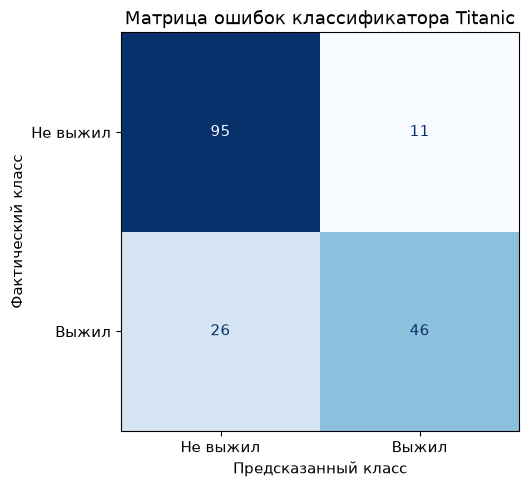

Верно предсказано: не выжил – 95 , выжил – 46
Ошибочно предсказано выживание: 11
Ошибочно предсказана гибель: 26


In [14]:
matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])
matrix_df = pd.DataFrame(
    matrix,
    index=['Факт: не выжил', 'Факт: выжил'],
    columns=['Прогноз: не выжил', 'Прогноз: выжил']
)
display(matrix_df)

fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay(matrix, display_labels=['Не выжил', 'Выжил']).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format='d'
)
ax.set(xlabel='Предсказанный класс', ylabel='Фактический класс',
       title='Матрица ошибок классификатора Titanic')
fig.tight_layout()
plt.show()

tn, fp, fn, tp = matrix.ravel()
print('Верно предсказано: не выжил –', tn, ', выжил –', tp)
print('Ошибочно предсказано выживание:', fp)
print('Ошибочно предсказана гибель:', fn)


### Задание №14. Доля верных ответов

Рассчитать accuracy.


In [15]:
accuracy = accuracy_score(y_test, y_pred)
majority_class = y_train.value_counts().idxmax()
baseline_pred = np.full(len(y_test), majority_class)
baseline_accuracy = accuracy_score(y_test, baseline_pred)
print(f'Accuracy: {accuracy:.4f} ({accuracy:.2%})')
print('Правильных прогнозов:', np.trace(matrix), 'из', len(y_test))
print(f'Accuracy постоянного прогноза класса {majority_class}: {baseline_accuracy:.2%}')


Accuracy: 0.7921 (79.21%)
Правильных прогнозов: 141 из 178
Accuracy постоянного прогноза класса 0: 59.55%


### Задание №15. Оценка результата

На тестовой выборке верно классифицирован 141 из 178 пассажиров, accuracy
составляет около 79,21%. Это выше accuracy постоянного прогноза наиболее
частого класса – около 59,55%. Среди выживших 26 пассажиров ошибочно отнесены
к погибшим, а среди погибших 11 – к выжившим.

Модель проверена на одной фиксированной тестовой части. Результат относится
к пассажирам, для которых остались заполнены используемые признаки;
строки с пропусками возраста или порта посадки в обучение и проверку не вошли.


## Вывод

Изучил подготовку данных и построение модели классификации методом ближайших соседей.


## Ответы на вопросы для защиты


### 1. Сформулируйте задачу классификации.

Классификация – определение класса объекта по его признакам на основе размеченных обучающих примеров. В работе признаки описывают пассажира, а классы – не выжил (0) и выжил (1).


### 2. Перечислите типы классификации.

По структуре ответов выделяют бинарную, мультиклассовую и классификацию по нескольким меткам. Несбалансированность описывает распределение количества объектов по классам и может встречаться в разных типах задач.


### 3. В чём особенность несбалансированной классификации?

В одних классах значительно больше объектов, чем в других. Высокая accuracy может достигаться за счёт частого класса при плохом распознавании редкого. Поэтому анализируют матрицу ошибок, precision, recall, F1 и при необходимости используют веса классов или изменение обучающей выборки.


### 4. В чём особенность мультиклассовой классификации?

Есть больше двух взаимоисключающих классов, и каждый объект относится к одному из них. Пример – определение одного из трёх видов ирисов по измерениям цветка.


### 5. В чём особенность бинарной классификации?

Есть два взаимоисключающих класса, обычно обозначаемых 0 и 1. Titanic в данной работе представляет бинарную задачу: для каждого пассажира предсказывается один из двух исходов.


### 6. В чём особенность классификации по нескольким меткам?

Один объект может одновременно иметь несколько меток. Например, текст может относиться и к спорту, и к путешествиям. Метки не обязаны исключать друг друга.


### 7. Чем один против всех отличается от одного против одного?

В стратегии один против всех для каждого из K классов обучают классификатор, отделяющий этот класс от остальных, всего K классификаторов. В стратегии один против одного обучают классификатор для каждой пары классов, всего K*(K-1)/2, затем объединяют их решения, например голосованием.


### 8. Что такое матрица ошибок?

Это таблица количеств объектов по сочетаниям фактического и предсказанного класса. В нашей матрице строки соответствуют факту, столбцы – прогнозу. При порядке классов [0, 1] элементы расположены как [[TN, FP], [FN, TP]]. Диагональ содержит правильные ответы, остальные клетки – ошибки.


### 9. Как рассчитывается accuracy?

Accuracy – количество правильных прогнозов, делённое на общее число проверенных объектов. Для бинарной задачи это (TP + TN) / (TP + TN + FP + FN). В работе получается (95 + 46) / 178, то есть примерно 0,7921.


### 10. Объясните алгоритм K ближайших соседей.

Для нового объекта рассчитывают расстояния до обучающих примеров, выбирают K ближайших и определяют класс по их голосованию. В работе K=4, используется обычное равное голосование. Поскольку расстояния зависят от масштаба признаков, перед KNN применяется StandardScaler. При выборе K учитывают, что слишком малое значение чувствительно к шуму, а слишком большое может сглаживать различия классов.
